# Eksploracyjna Analiza Danych dla przetworzonych danych

## Importowanie bibliotek

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import os 
from datetime import datetime, timedelta


## Ładowanie Danych

In [3]:
DATA_ARRAY = {}
directory = '../data/enriched'
for file in os.listdir(directory):
    file_path = os.path.join(directory,file)
    dates_from_filename = file.removesuffix('.csv').removeprefix('enriched-')
    finish_date = datetime.strptime(dates_from_filename, '%d-%m-%Y')
    start_date = finish_date - timedelta(days=5)
    df = pd.read_csv(file_path)
    DATA_ARRAY[start_date.strftime('%d-%m-%Y') + ' do ' + finish_date.strftime('%d-%m-%Y') ] = df

compacted_data = pd.concat(DATA_ARRAY)




## Sprawdzenie tabel z każdego okresu akwizycji danych

### Wymiary tabel i podstawowe dane

In [4]:
for key, df in DATA_ARRAY.items():
    print(f'-------------{key}-------------\n')
    print('Ilość kolumn:', df.shape[1])
    print('Ilość wierszy:',df.shape[0])
    print('Typy danych kolumn:')
    print(df.dtypes,'\n')
    print('Ilość wartości Nan:')
    print(df.isnull().sum())
    


-------------12-10-2026 do 17-10-2026-------------

Ilość kolumn: 15
Ilość wierszy: 313
Typy danych kolumn:
date              object
link              object
title             object
content           object
company_name      object
ticker            object
category          object
source            object
initial price    float64
+5 min           float64
+10 min          float64
+15 min          float64
+30 min          float64
+60 min          float64
rate             float64
dtype: object 

Ilość wartości Nan:
date               0
link               1
title              1
content            1
company_name       1
ticker             1
category           0
source             0
initial price    220
+5 min           220
+10 min          222
+15 min          220
+30 min          222
+60 min          226
rate             211
dtype: int64
-------------18-10-2026 do 23-10-2026-------------

Ilość kolumn: 15
Ilość wierszy: 502
Typy danych kolumn:
date              object
link              ob

## Duplikaty

Ponieważ w poprzednie analizie danych, dokonaliśmy czysczenia poprzez usuwanie duplikatów w kolumnie z linkami, tytułami oraz zawartością. Tutaj tylko upewnimy się czy nie wkradły się niepożądane duplikaty.

### Sprawdzenie duplikatów w kolumnach link, title, content

In [5]:
for key, df in DATA_ARRAY.items():
    print(f'-------------{key}[link]-------------\n')
    dups = df.pivot_table(index = ['link'], aggfunc ='size')
    print(dups[dups > 1])
    print(f'-------------{key}[title]-------------\n')
    dups = df.pivot_table(index = ['title'], aggfunc ='size')
    print(dups[dups > 1])
    print(f'-------------{key}[content]-------------\n')
    dups = df.pivot_table(index = ['content'], aggfunc ='size')
    print(dups[dups > 1])




-------------12-10-2026 do 17-10-2026[link]-------------

Series([], dtype: int64)
-------------12-10-2026 do 17-10-2026[title]-------------

Series([], dtype: int64)
-------------12-10-2026 do 17-10-2026[content]-------------

Series([], dtype: int64)
-------------18-10-2026 do 23-10-2026[link]-------------

Series([], dtype: int64)
-------------18-10-2026 do 23-10-2026[title]-------------

Series([], dtype: int64)
-------------18-10-2026 do 23-10-2026[content]-------------

Series([], dtype: int64)
-------------25-10-2026 do 30-10-2026[link]-------------

Series([], dtype: int64)
-------------25-10-2026 do 30-10-2026[title]-------------

Series([], dtype: int64)
-------------25-10-2026 do 30-10-2026[content]-------------

Series([], dtype: int64)


Teraz mamy pewność, że pozbyliśmy się wszystkich duplikatów.

### Duplikaty w kolumnie company_name

In [6]:
for key, df in DATA_ARRAY.items():
    print(f'-------------{key}[company_name]-------------\n')
    dups = df.pivot_table(index = ['company_name'], aggfunc ='size')
    print(dups[dups > 1])

-------------12-10-2026 do 17-10-2026[company_name]-------------

company_name
Nan          210
alior          4
allegro        4
budimex        8
cdprojekt      4
erste          3
kghm          11
kruk           2
pepco          2
pge           12
pknorlen      23
pkobp         14
pzu            2
zabka          8
dtype: int64
-------------18-10-2026 do 23-10-2026[company_name]-------------

company_name
Nan          326
alior          5
allegro        7
budimex        6
cdprojekt      9
kghm          24
kruk           2
mbank          5
modivo         2
orangepl       3
pekao          7
pepco         15
pge           27
pknorlen      36
pkobp         14
pzu            6
zabka          3
dtype: int64
-------------25-10-2026 do 30-10-2026[company_name]-------------

company_name
Nan          334
alior         11
allegro        4
budimex       34
cdprojekt      3
erste         21
kety           9
kghm          16
kruk           6
lpp            6
mbank         28
modivo         3
orange

Widać, że wiele duplikatów wynika z nazewnictwa pustej komórki dla nie dopasownanych wiadomości ze spółek poprzez "Nan". Dzieje się tak, ponieważ model w swojej instrukcji ma podane aby konkretnie odpowiadać gdy nie może dopasować spółki "Nan". Jest to motywowanem tym, aby model nie halucynował i nie podawał "czegokolwiek", dlatego powstała dokładna instrukcja aby takim spółkom "nadawać nazwę Nan".

## Usuwanie wartości pustych

Aby mieć czyste dane gotowe do ewaluacji, najpierw z datasetu trzeba usunąć puste komórki. Będziemy działać na całym zbiorze danych


### Puste komórki w kolumnie company_name

In [7]:
compacted_data = compacted_data[compacted_data.company_name != "Nan"]
compacted_data['company_name'].dropna()
print(compacted_data['company_name'].unique())

print(compacted_data['company_name'].value_counts())


['erste' 'kghm' 'cdprojekt' 'pknorlen' 'pkobp' 'pge' 'pzu' 'alior' 'zabka'
 'allegro' 'pepco' 'pekao' 'budimex' 'kruk' 'lpp' 'kety' 'mbank' nan
 'orangepl' 'dinopl' 'modivo']
company_name
pknorlen     102
pge           53
kghm          51
pkobp         50
budimex       48
mbank         34
pekao         26
zabka         26
erste         25
alior         20
pepco         18
cdprojekt     16
orangepl      15
allegro       15
kety          11
kruk          10
pzu            8
lpp            8
modivo         5
dinopl         1
Name: count, dtype: int64


### Puste komórki w kolumnach z ceną akcji w interwałach

In [15]:
price_cols = ['initial price', '+5 min', '+10 min', '+15 min', '+30 min', '+60 min']

compacted_data = compacted_data.dropna(subset=price_cols)
print(compacted_data.isnull().sum())


date             0
link             0
title            0
content          0
company_name     0
ticker           0
category         0
source           0
initial price    0
+5 min           0
+10 min          0
+15 min          0
+30 min          0
+60 min          0
rate             0
dtype: int64


Teraz gdy pozbyliśmy się duplikatów i pustych komórek, można się przyjrzeć co i ile nam zostało.

## Wizualizacja danych podzielonych na kategorie i źródła 

### Wymiary danych dla poszczególnych źródeł

In [16]:
print('-------Skumulowane dane-------\n')
print("Źródła:", compacted_data['source'].value_counts())
print()

print('Kategorie:', compacted_data['category'].value_counts())

-------Skumulowane dane-------

Źródła: source
pap        309
bankier    157
wykop        5
Name: count, dtype: int64

Kategorie: category
profiles       181
bankier        157
market          89
economy         39
gospodarka       3
technologia      2
Name: count, dtype: int64


Kategorie economy, market i profiles należą do pap, technologia, finanse, gospodarka, inwestycje należą do wykop, a bankier jak sama nazwa wskazuję do bankier

## Wizualizacja danych

### Źródła

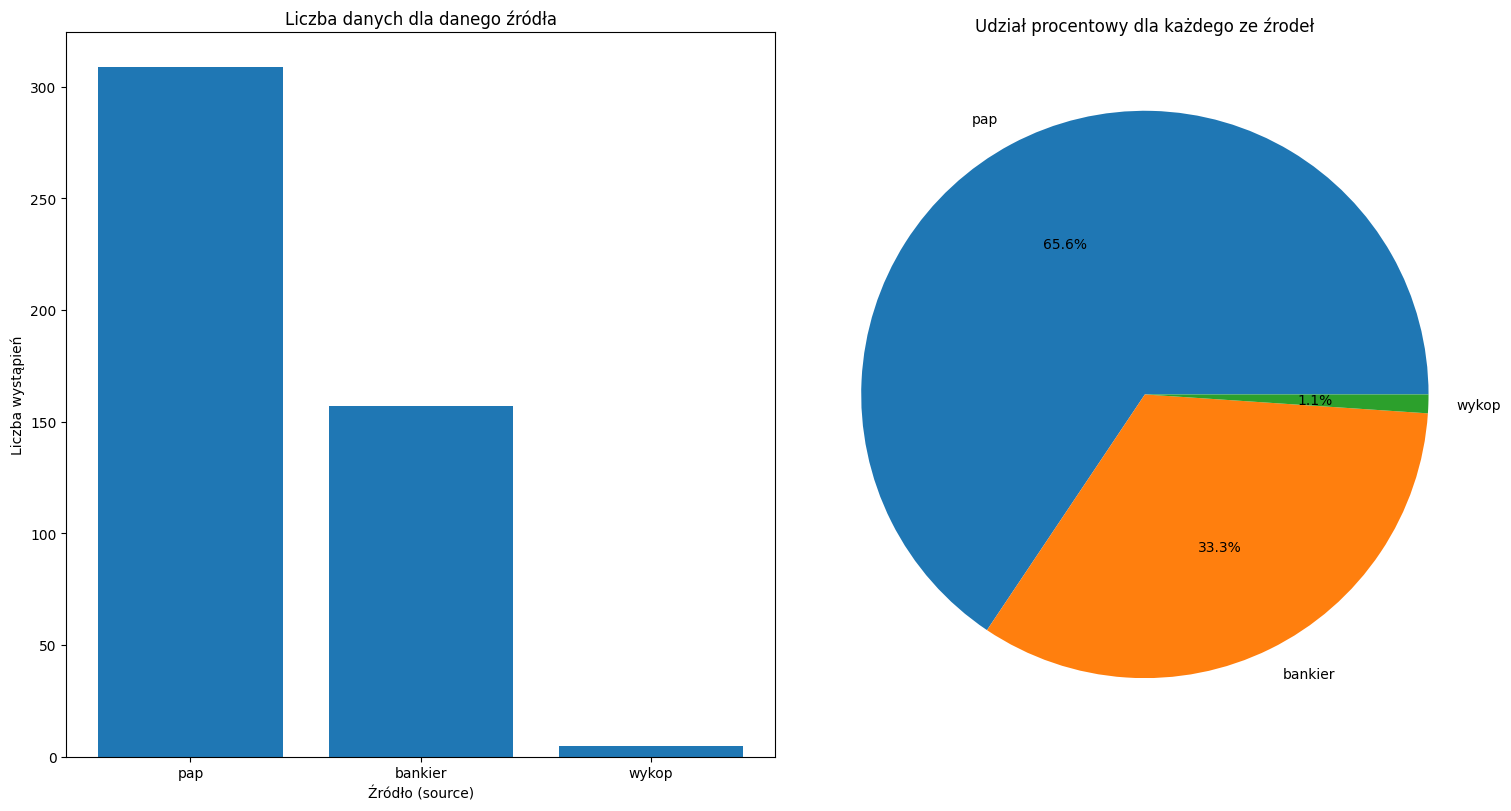

In [25]:
counts = compacted_data['source'].value_counts()

fig, ax = plt.subplots(1,2, figsize=(15,8), constrained_layout=True)
ax[0].bar(x=counts.index, height=counts.values,)
ax[0].set(xlabel = 'Źródło (source)', ylabel = 'Liczba wystąpień')
ax[0].set_title('Liczba danych dla danego źródła')
ax[1].pie(counts.values, labels=counts.index, autopct='%1.1f%%')
ax[1].set_title('Udział procentowy dla każdego ze źrodeł')
plt.show()

### Kategorie Pap

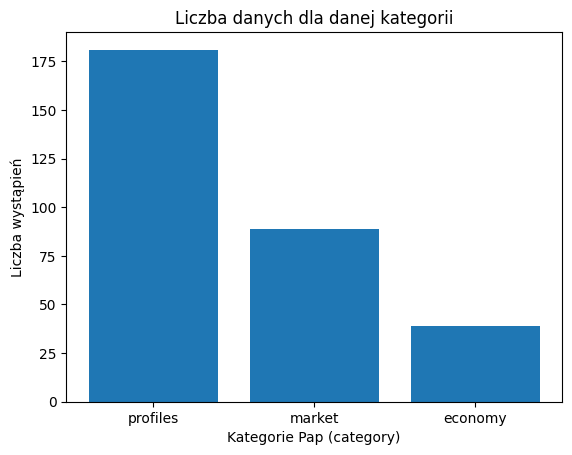

In [18]:
counts = compacted_data[compacted_data['source'] == 'pap']['category'].value_counts()

plt.bar(x=counts.index, height=counts.values)
plt.xlabel('Kategorie Pap (category)')
plt.ylabel('Liczba wystąpień')
plt.title('Liczba danych dla danej kategorii')
plt.show()

### Kategoria Bankier

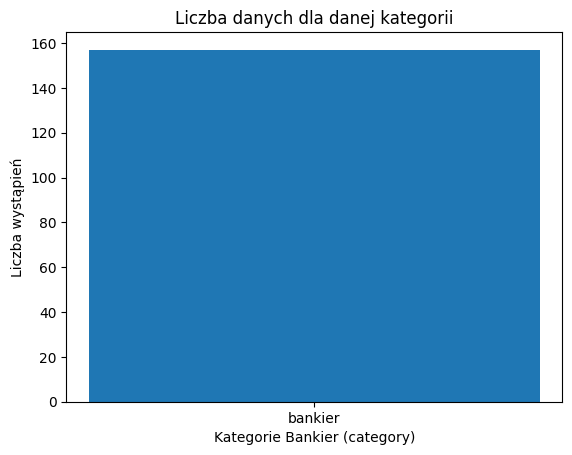

In [19]:
counts = compacted_data[compacted_data['source'] == 'bankier']['category'].value_counts()

plt.bar(x=counts.index, height=counts.values)
plt.xlabel('Kategorie Bankier (category)')
plt.ylabel('Liczba wystąpień')
plt.title('Liczba danych dla danej kategorii')
plt.show()

Kategorie Wykop

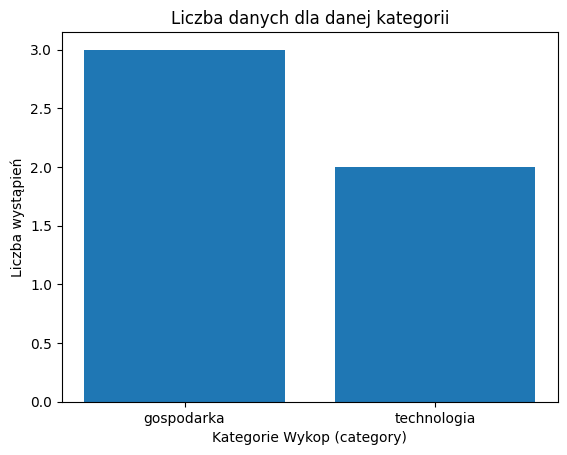

In [20]:
counts = compacted_data[compacted_data['source'] == 'wykop']['category'].value_counts()
plt.bar(x=counts.index, height=counts.values)
plt.xlabel('Kategorie Wykop (category)')
plt.ylabel('Liczba wystąpień')
plt.title('Liczba danych dla danej kategorii')
plt.show()

## Dane numeryczne

kolumna rate

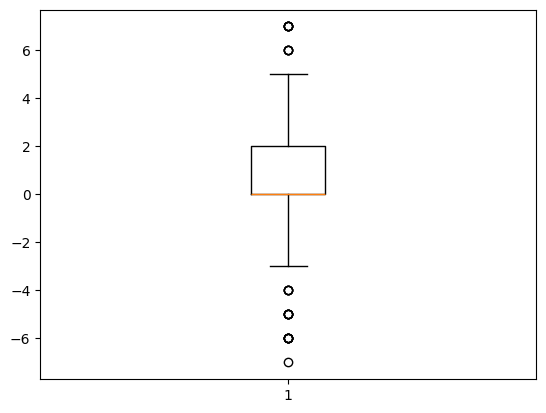

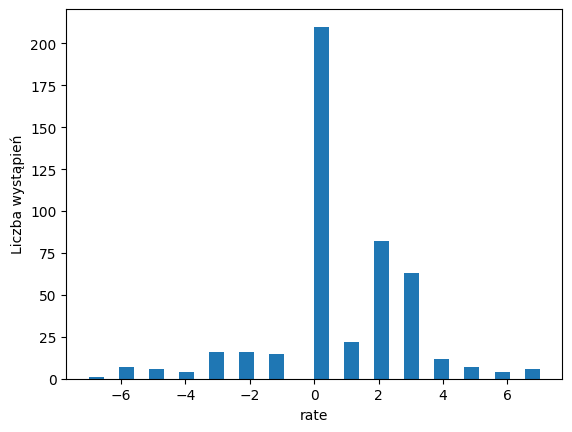

In [29]:
plt.boxplot(compacted_data['rate'])
plt.show()
plt.hist(compacted_data['rate'].dropna(), bins=30)
plt.xlabel('rate'); plt.ylabel('Liczba wystąpień')
plt.show()